# E01 CLAUDIO ENCARNACIÓN

- Trabaja con "e01_datos.csv".
- Entrega un notebook ejecutado con interpretación de cada celda de código que uses.
- Usa validación cruzada.
- Cualquier observación eliminada debe ser justificada.
- El archivo tiene errores deliberados. Detéctalos y documenta cómo los resolviste.
- Sólo está permitido usar sklearn

- Variables:

y es la respuesta continua
x1, x2 y x3 son variable numéricas
grupo es una variable cualitativa esperada con categorías A, B y C
Rúbrica:

- EDA + limpieza
- Modelo lineal múltiple
- 6 errores comunes
- Mejora y comparación de modelos
- Validación cruzada y conclusión

In [1]:
import pandas as pd


In [34]:
df = pd.read_csv("/Users/claudioalejoencarnacionmartinez/Downloads/e01_datos.csv")
df.head(15)

,y,x1,x2,x3,grupo
0,13.643473,3.745401188473625,1.869147,6.363906,B
1,14.226813,9.50714306409916,6.743883,4.379466,A
2,15.312343,7.319939418114051,6.466175,5.648333,A
3,15.850062,5.986584841970366,3.012901,4.739714,A
4,15.477359,1.5601864044243652,1.443092,5.193992,B
5,15.461247,1.5599452033620265,2.738530,6.190314,a
6,8.125659,0.5808361216819946,-1.493353,3.363559,A
7,14.482023,8.661761457749352,6.717882,9.184775,C
8,19.990525,6.011150117432088,4.820222,2.987965,B
9,13.626733,7.080725777960454,6.248732,2.571623,A


In [35]:
df.head(90)

,y,x1,x2,x3,grupo
0,13.643473,3.745401188473625,1.869147,6.363906,B
1,14.226813,9.50714306409916,6.743883,4.379466,A
2,15.312343,7.319939418114051,6.466175,5.648333,A
3,15.850062,5.986584841970366,3.012901,4.739714,A
4,15.477359,1.5601864044243652,1.443092,5.193992,B
...,...,...,...,...,...
85,11.080766,3.2518332202674705,0.198157,3.801250,A
86,18.436389,7.29606178338064,6.295559,5.010487,B
87,12.499392,6.375574713552132,2.846422,5.093961,A
88,18.813001,"7,654",6.087777,4.099869,B


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 183 entries, 0 to 182
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   y       183 non-null    float64
 1   x1      183 non-null    str    
 2   x2      181 non-null    float64
 3   x3      182 non-null    float64
 4   grupo   182 non-null    str    
dtypes: float64(3), str(2)
memory usage: 7.3 KB


In [4]:
df.describe()

,y,x2,x3
count,183.000000,181.000000,182.000000
mean,14.053933,3.656675,5.054328
std,4.214684,2.596806,1.997665
min,4.000000,-2.194452,0.396158
25%,11.692237,1.603202,3.518048
50%,13.510425,3.463986,4.992027
75%,15.982460,5.689776,6.327197
max,42.000000,10.739239,11.157762


Eliminar fila 12, donde el valor de x1 no puede convertirse a float

In [36]:
df = df.drop(df.index[12])
df.head(15)

,y,x1,x2,x3,grupo
0,13.643473,3.745401188473625,1.869147,6.363906,B
1,14.226813,9.50714306409916,6.743883,4.379466,A
2,15.312343,7.319939418114051,6.466175,5.648333,A
3,15.850062,5.986584841970366,3.012901,4.739714,A
4,15.477359,1.5601864044243652,1.443092,5.193992,B
5,15.461247,1.5599452033620265,2.738530,6.190314,a
6,8.125659,0.5808361216819946,-1.493353,3.363559,A
7,14.482023,8.661761457749352,6.717882,9.184775,C
8,19.990525,6.011150117432088,4.820222,2.987965,B
9,13.626733,7.080725777960454,6.248732,2.571623,A


In [37]:
df = df.drop(df.index[87])
df.head(90)

,y,x1,x2,x3,grupo
0,13.643473,3.745401188473625,1.869147,6.363906,B
1,14.226813,9.50714306409916,6.743883,4.379466,A
2,15.312343,7.319939418114051,6.466175,5.648333,A
3,15.850062,5.986584841970366,3.012901,4.739714,A
4,15.477359,1.5601864044243652,1.443092,5.193992,B
...,...,...,...,...,...
86,18.436389,7.29606178338064,6.295559,5.010487,B
87,12.499392,6.375574713552132,2.846422,5.093961,A
89,18.341894,4.722149251619493,4.848353,6.245700,B
90,9.227962,1.195942459383017,0.974093,2.864759,A


## Convertir variable x1 a float

In [41]:
df['x1'] = df['x1'].astype(float)
df.info()

<class 'pandas.DataFrame'>
Index: 181 entries, 0 to 182
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   y       181 non-null    float64
 1   x1      181 non-null    float64
 2   x2      179 non-null    float64
 3   x3      180 non-null    float64
 4   grupo   180 non-null    str    
dtypes: float64(4), str(1)
memory usage: 8.5 KB


## Eliminar valores nulos

In [43]:
df = df.dropna()

In [44]:
df.info()

<class 'pandas.DataFrame'>
Index: 177 entries, 0 to 182
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   y       177 non-null    float64
 1   x1      177 non-null    float64
 2   x2      177 non-null    float64
 3   x3      177 non-null    float64
 4   grupo   177 non-null    str    
dtypes: float64(4), str(1)
memory usage: 8.3 KB


In [45]:
df['grupo'].unique()

<StringArray>
['B', 'A', 'a', 'C', ' B ', 'grupo_c', 'AA', 'c', 'b', 'D']
Length: 10, dtype: str

## Reemplazar los valores mal escritos de la columna Grupo, y checar con .unique()

In [47]:
df['grupo'] = df['grupo'].str.replace("a", "A")
df['grupo'] = df['grupo'].str.replace("AA", "A")
df['grupo'] = df['grupo'].str.replace("b", "B")
df['grupo'] = df['grupo'].str.replace("c", "C")
df['grupo'] = df['grupo'].str.replace("grupo_C", "C")
df['grupo'] = df['grupo'].str.replace(" B ", "B")
df['grupo'].unique()

<StringArray>
['B', 'A', 'C', 'D']
Length: 4, dtype: str

In [48]:
df.info()

<class 'pandas.DataFrame'>
Index: 177 entries, 0 to 182
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   y       177 non-null    float64
 1   x1      177 non-null    float64
 2   x2      177 non-null    float64
 3   x3      177 non-null    float64
 4   grupo   177 non-null    str    
dtypes: float64(4), str(1)
memory usage: 8.3 KB


## Usar OneHotEncoder para la variable categórica

In [49]:
from sklearn.preprocessing import OneHotEncoder

In [50]:
onehot_encoder = OneHotEncoder(categories = [['A', 'B', 'C', 'D']])
df[['A','B', 'C', 'D']] = onehot_encoder.fit_transform(df[['grupo']]).toarray()
df.head(5)


,y,x1,x2,x3,grupo,A,B,C,D
0,13.643473,3.745401,1.869147,6.363906,B,0.0,1.0,0.0,0.0
1,14.226813,9.507143,6.743883,4.379466,A,1.0,0.0,0.0,0.0
2,15.312343,7.319939,6.466175,5.648333,A,1.0,0.0,0.0,0.0
3,15.850062,5.986585,3.012901,4.739714,A,1.0,0.0,0.0,0.0
4,15.477359,1.560186,1.443092,5.193992,B,0.0,1.0,0.0,0.0


## Eliminar columna head

In [54]:
df = df.drop(columns=['grupo'])
df.head()

,y,x1,x2,x3,A,B,C,D
0,13.643473,3.745401,1.869147,6.363906,0.0,1.0,0.0,0.0
1,14.226813,9.507143,6.743883,4.379466,1.0,0.0,0.0,0.0
2,15.312343,7.319939,6.466175,5.648333,1.0,0.0,0.0,0.0
3,15.850062,5.986585,3.012901,4.739714,1.0,0.0,0.0,0.0
4,15.477359,1.560186,1.443092,5.193992,0.0,1.0,0.0,0.0


## Regresión

In [55]:
from sklearn.linear_model import LinearRegression

In [59]:
X = df[['x1','x2','x3','A','B', 'C', 'D']]
y = df['y']

lr = LinearRegression()
lr.fit(X, y)
print("Coeficients:", lr.coef_)
print("Intercept:", lr.intercept_)

Coeficients: [ 0.65409473  0.21094169  0.66304528  0.04408029  2.76154064 -2.1877546
 -0.61786632]
Intercept: 6.402697793286575


## Visualizar el análisis de residuos

In [60]:
import numpy as np
import matplotlib.pyplot as plt

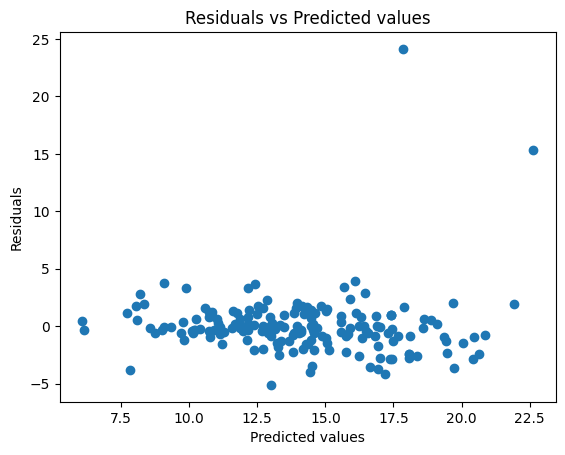

In [64]:
ypred = lr.predict(X)
residuos = y - ypred

plt.scatter(ypred, residuos)
plt.xlabel("Predicted values")
plt.ylabel("Residuals")
plt.title("Residuals vs Predicted values")
plt.show()

### Se observa homocedasticidad en los residuos, algunos outliers (solo 2), se observa linealidad (no hay una curva)